# Student Academic Performance Prediction Report

## 0. Dependencies and Configuration

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

RANDOM_STATE = 69

## 1. Project Team
- Itmam Alam
- Akos Papp

## 2. Dataset Overview

### Data Source
The dataset originates from the UC Irvine Machine Learning Repository and focuses on predicting student dropout and academic success. The data can be accessed at:
[https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success)

### Dataset Description
This dataset contains academic and socioeconomic information about students, designed for a three-class classification problem. The target variable represents student outcomes: **Dropout**, **Enrolled**, or **Graduate**. The dataset includes comprehensive information about student demographics, academic performance, family background, and economic indicators.

In [41]:
dataset = pd.read_csv('data.csv', sep=';')

# Clean column names by removing tab characters
dataset.columns = dataset.columns.str.replace('\t', '', regex=False)

# Separate features and target
features = dataset[dataset.columns[:-1]]
target = dataset['Target']

print(f"Dataset shape: {dataset.shape}")
print(f"Number of features: {features.shape[1]}")
print(f"Target classes: {target.unique()}")

Dataset shape: (4424, 37)
Number of features: 36
Target classes: ['Dropout' 'Graduate' 'Enrolled']


### Initial Data Exploration

In [42]:
print("Dataset Information:")
print(dataset.info())
print("\nFirst 5 rows:")
print(dataset.head())
print("\nStatistical Summary:")
print(dataset.describe())
print("\nTarget Distribution:")
print(target.value_counts())
print("\nMissing Values:")
print(dataset.isnull().sum().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualificati

## 3. Exploratory Data Analysis

### Class Distribution Analysis

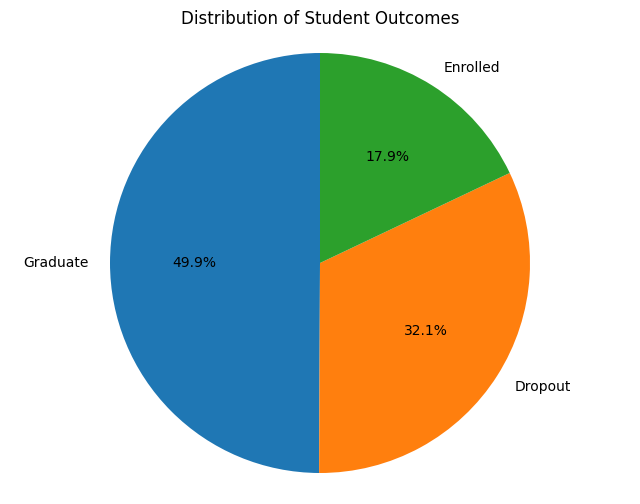

Class Distribution:
Graduate: 2209 (49.9%)
Dropout: 1421 (32.1%)
Enrolled: 794 (17.9%)


In [43]:
plt.figure(figsize=(8, 6))
target_counts = target.value_counts()
plt.pie(target_counts.values, labels=target_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Student Outcomes')
plt.axis('equal')
plt.show()

print("Class Distribution:")
for class_name, count in target_counts.items():
    percentage = (count / len(target)) * 100
    print(f"{class_name}: {count} ({percentage:.1f}%)")

The dataset exhibits a notable class imbalance, with graduates representing the majority class. This distribution reflects real-world educational outcomes but may influence model performance, potentially creating a bias toward predicting the majority class. Such imbalances require careful consideration during model training and evaluation.

### Feature Correlation Analysis

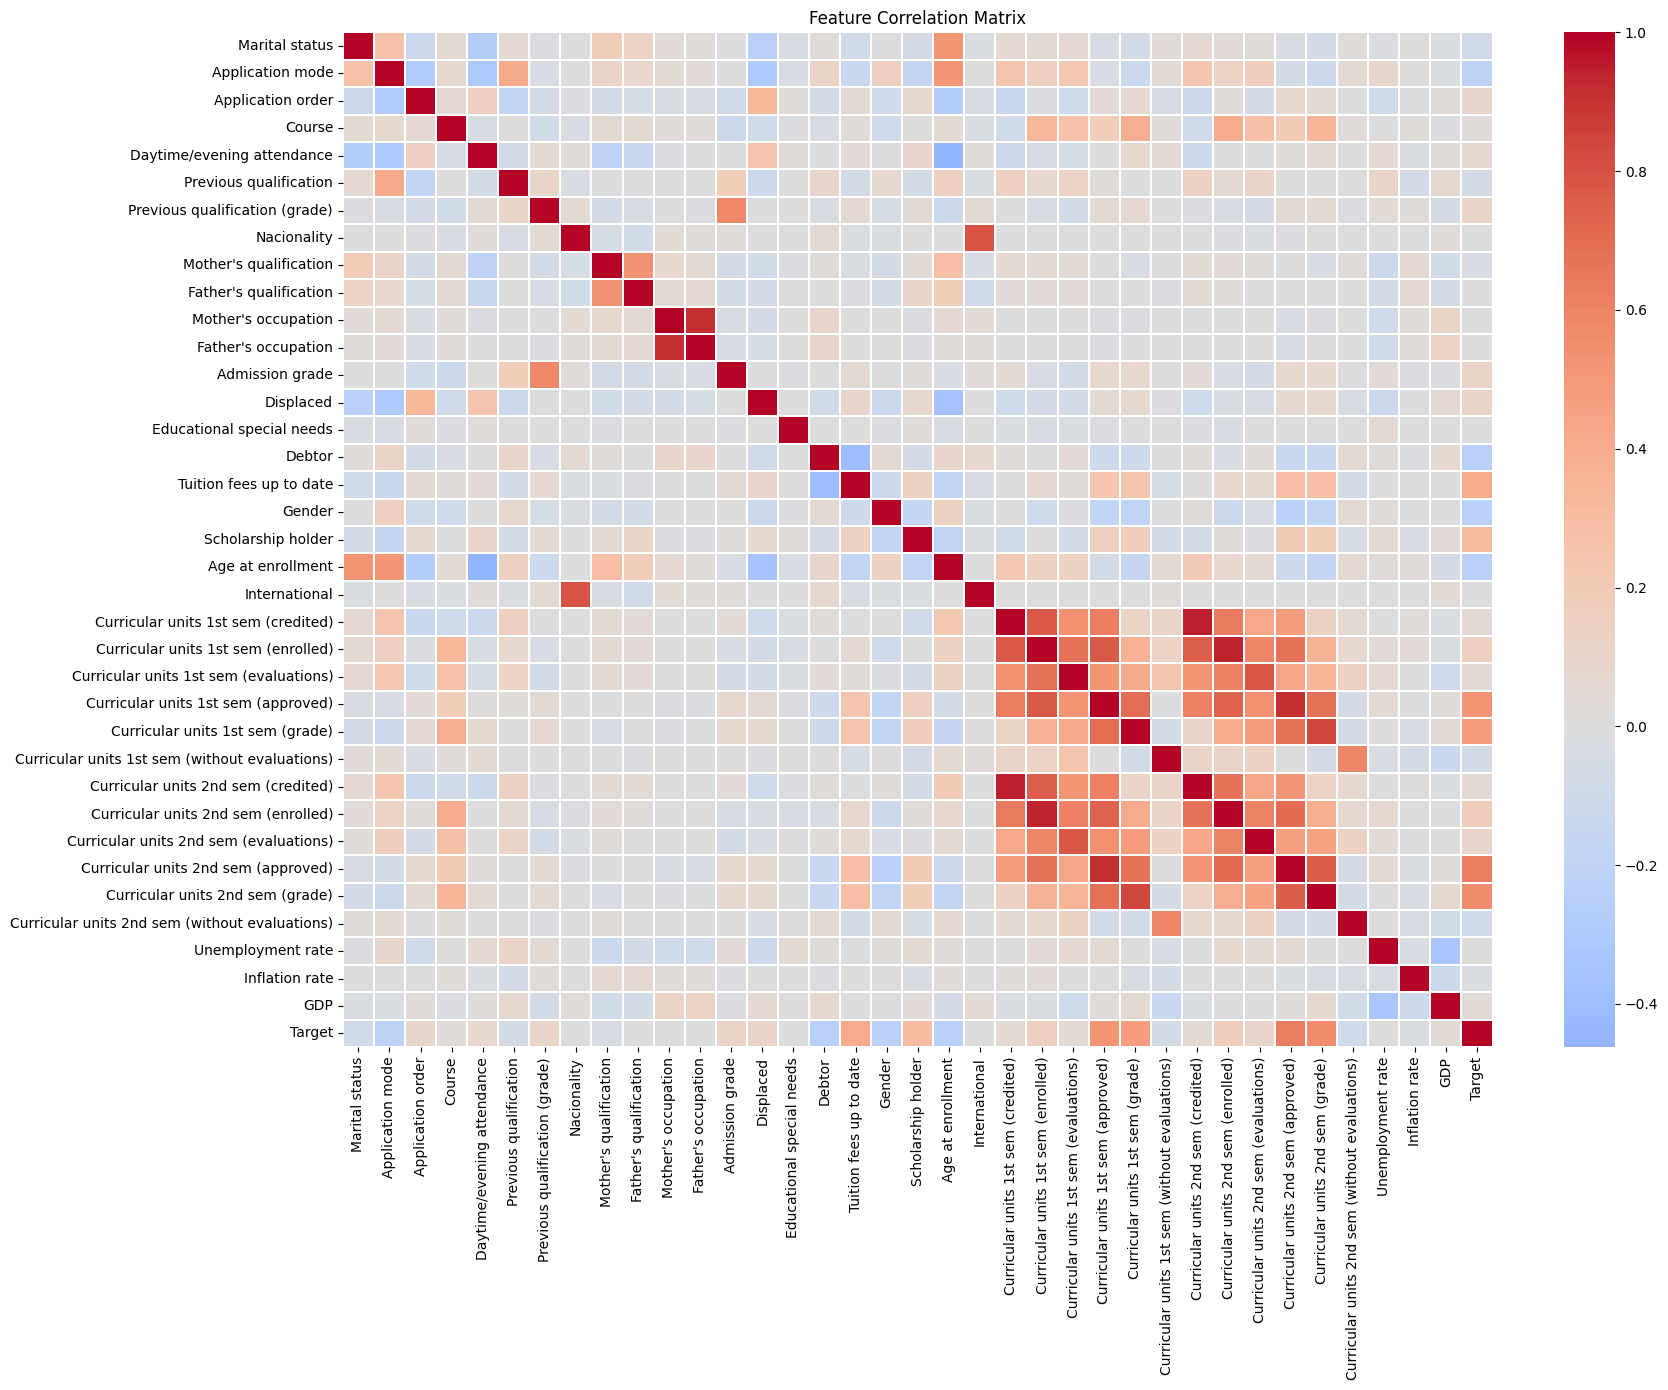

Top 10 Features Correlated with Target:
Curricular units 2nd sem (approved)    0.624157
Curricular units 2nd sem (grade)       0.566827
Curricular units 1st sem (approved)    0.529123
Curricular units 1st sem (grade)       0.485207
Tuition fees up to date                0.409827
Scholarship holder                     0.297595
Age at enrollment                     -0.243438
Debtor                                -0.240999
Gender                                -0.229270
Application mode                      -0.221747
Name: Target, dtype: float64


In [44]:
dataset_encoded = dataset.copy()
encoder = LabelEncoder()
dataset_encoded['Target'] = encoder.fit_transform(dataset['Target'])

correlation_matrix = dataset_encoded.corr()
plt.figure(figsize=(18, 14))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0, linewidths=0.1)
plt.title('Feature Correlation Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

target_correlations = correlation_matrix['Target'].drop('Target').sort_values(key=abs, ascending=False)
print("Top 10 Features Correlated with Target:")
print(target_correlations.head(10))

### Financial Factors Impact

<Figure size 1000x600 with 0 Axes>

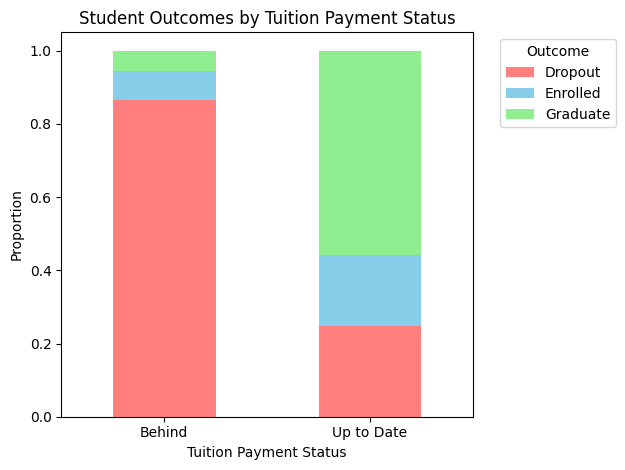

In [45]:
tuition_mapping = {1: 'Up to Date', 0: 'Behind'}
crosstab_result = pd.crosstab(dataset['Tuition fees up to date'].map(tuition_mapping), 
                              dataset['Target'], normalize='index')

plt.figure(figsize=(10, 6))
crosstab_result.plot(kind='bar', stacked=True, color=['#ff7f7f', '#87ceeb', '#90ee90'])
plt.title('Student Outcomes by Tuition Payment Status')
plt.xlabel('Tuition Payment Status')
plt.ylabel('Proportion')
plt.legend(title='Outcome', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Gender-Based Performance Analysis

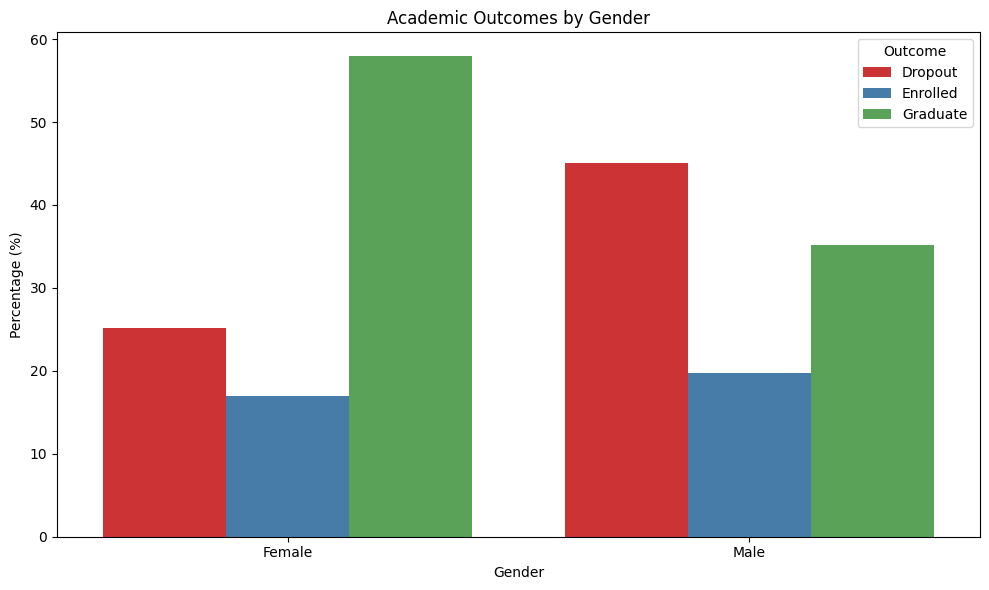

Gender-based outcome summary:

Male:
  Dropout: 45.1%
  Enrolled: 19.7%
  Graduate: 35.2%

Female:
  Dropout: 25.1%
  Enrolled: 17.0%
  Graduate: 57.9%


In [46]:
gender_analysis = dataset.groupby(['Gender', 'Target']).size().reset_index(name='count')
gender_totals = gender_analysis.groupby('Gender')['count'].transform('sum')
gender_analysis['percentage'] = gender_analysis['count'] / gender_totals * 100

gender_labels = {1: 'Male', 0: 'Female'}
gender_analysis['Gender_Label'] = gender_analysis['Gender'].map(gender_labels)

plt.figure(figsize=(10, 6))
sns.barplot(data=gender_analysis, x='Gender_Label', y='percentage', hue='Target', palette='Set1')
plt.title('Academic Outcomes by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage (%)')
plt.legend(title='Outcome')
plt.tight_layout()
plt.show()

print("Gender-based outcome summary:")
for gender, label in gender_labels.items():
    gender_data = gender_analysis[gender_analysis['Gender'] == gender]
    print(f"\n{label}:")
    for _, row in gender_data.iterrows():
        print(f"  {row['Target']}: {row['percentage']:.1f}%")

## 4. Data Quality Assessment

### Data Cleaning Evaluation

The dataset underwent comprehensive quality assessment to determine if preprocessing steps were necessary:

**Missing Values Analysis**: A thorough examination revealed no missing values across all features and target variables, eliminating the need for imputation strategies.

**Data Integrity Check**: All values were found to be within expected ranges and properly formatted, with no evidence of incorrect or corrupted entries.

**Feature Adequacy Assessment**: The existing feature set was determined to be comprehensive and well-structured, requiring no additional feature engineering or removal.

**Data Integration**: The dataset was provided as a single, well-integrated file, eliminating the need for merging multiple data sources.

**Conclusion**: Based on this assessment, no data cleaning procedures were required. The dataset is ready for analysis and model development in its original form.

## 5. Data Preparation for Machine Learning

### Train-Test Split with Stratification

To ensure reliable model evaluation, the dataset was divided into training and testing sets while maintaining the original class distribution through stratification.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    features, target, 
    test_size=0.3, 
    random_state=RANDOM_STATE, 
    stratify=target
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
print(f"Feature dimensions: {X_train.shape[1]}")

print("\nClass distribution in training set:")
print(y_train.value_counts(normalize=True).round(3))
print("\nClass distribution in testing set:")
print(y_test.value_counts(normalize=True).round(3))

Training set size: 3096 samples
Testing set size: 1328 samples
Feature dimensions: 36

Class distribution in training set:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64

Class distribution in testing set:
Target
Graduate    0.499
Dropout     0.322
Enrolled    0.179
Name: proportion, dtype: float64


### Random Forest Pipeline Configuration

Random Forest was selected as the primary algorithm for this classification task due to its robust performance with mixed data types and inherent feature importance capabilities.

In [48]:
rf_pipeline = Pipeline([
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
])

print("Random Forest Pipeline created successfully")
print("Pipeline steps:", [step[0] for step in rf_pipeline.steps])

Random Forest Pipeline created successfully
Pipeline steps: ['classifier']


## 6. Model Optimization and Training

### Hyperparameter Tuning with Grid Search

To achieve optimal performance, we conducted systematic hyperparameter optimization using GridSearchCV with 5-fold cross-validation.

In [49]:
param_grid = {
    'classifier__n_estimators': [50, 100, 150, 200],
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__bootstrap': [True, False]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Starting hyperparameter optimization...")
grid_search.fit(X_train, y_train)

print(f"Best cross-validation score: {grid_search.best_score_:.4f}")
print("Optimal hyperparameters:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")

Starting hyperparameter optimization...
Fitting 5 folds for each of 384 candidates, totalling 1920 fits


Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 295, in main
    raise ValueError(
        f'Cannot register {name} for automatic cleanup: '
        f'unknown resource type {rtype}')
ValueError: Cannot register /dev/shm/joblib_memmapping_folder_5081_05fc58aaa70d4b938689b9bab67be0b7_2654cd0a4f63424a943167348d0c7093 for automatic cleanup: unknown resource type folder
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 295, in main
    raise ValueError(
        f'Cannot register {name} for automatic cleanup: '
        f'unknown resource type {rtype}')
ValueError: Cannot register /loky-5081-yhw7akwc for automatic cleanup: unknown resource type semlock
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 295, in main
    raise ValueError(
        f'Cannot register {name} for automatic cleanup: '
        f'unknown resource type {

Best cross-validation score: 0.7710
Optimal hyperparameters:
  classifier__bootstrap: False
  classifier__criterion: gini
  classifier__max_depth: None
  classifier__max_features: log2
  classifier__min_samples_leaf: 1
  classifier__n_estimators: 100


## 7. Model Evaluation and Results

### Performance Metrics on Test Set

In [50]:
optimized_model = grid_search.best_estimator_
test_predictions = optimized_model.predict(X_test)

evaluation_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "F1 Score": f1_score(y_test, test_predictions, average='weighted'),
    "Precision": precision_score(y_test, test_predictions, average='weighted'),
    "Recall": recall_score(y_test, test_predictions, average='weighted'),
    "Matthews Correlation Coefficient": matthews_corrcoef(y_test, test_predictions)
}

print("Random Forest Model Performance:")
print("=" * 40)
for metric, score in evaluation_metrics.items():
    print(f"{metric}: {score:.4f}")

results_df = pd.DataFrame([evaluation_metrics])
results_df.index = ['Random Forest']
print("\nResults Summary:")
print(results_df.round(4))

Random Forest Model Performance:
Accuracy: 0.7794
F1 Score: 0.7692
Precision: 0.7667
Recall: 0.7794
Matthews Correlation Coefficient: 0.6344

Results Summary:
               Accuracy  F1 Score  Precision  Recall  \
Random Forest    0.7794    0.7692     0.7667  0.7794   

               Matthews Correlation Coefficient  
Random Forest                            0.6344  


### Feature Importance Analysis

/tmp/ipykernel_5081/1431256697.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_features, x='Importance', y='Feature', palette='viridis')


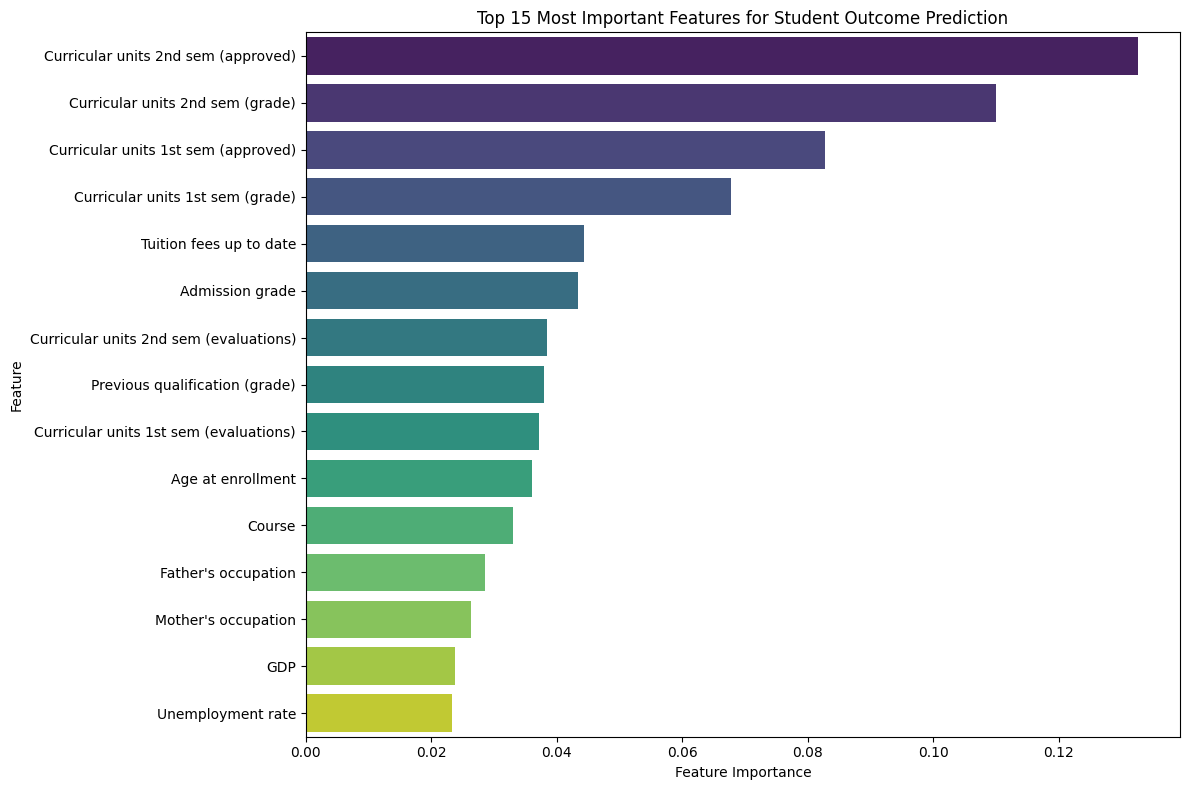

Top 10 Most Important Features:
 1. Curricular units 2nd sem (approved): 0.1327
 2. Curricular units 2nd sem (grade): 0.1100
 3. Curricular units 1st sem (approved): 0.0827
 4. Curricular units 1st sem (grade): 0.0678
 5. Tuition fees up to date: 0.0444
 6. Admission grade: 0.0434
 7. Curricular units 2nd sem (evaluations): 0.0384
 8. Previous qualification (grade): 0.0380
 9. Curricular units 1st sem (evaluations): 0.0371
10. Age at enrollment: 0.0361


: 

In [ ]:
feature_importance = optimized_model.named_steps['classifier'].feature_importances_
importance_df = pd.DataFrame({
    'Feature': features.columns,
    'Importance': feature_importance
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 8))
top_features = importance_df.head(15)
sns.barplot(data=top_features, x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Most Important Features for Student Outcome Prediction')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()

print("Top 10 Most Important Features:")
for i, (_, row) in enumerate(importance_df.head(10).iterrows(), 1):
    print(f"{i:2d}. {row['Feature']}: {row['Importance']:.4f}")

### Decision Boundary Visualization

In [ ]:
# --- Plot decision surface without altering the model ---
def plot_decision_surface(model, X, Y, ax=None, title=None):
    h = .05
    x_min, x_max = X.iloc[:, 0].min() - .5, X.iloc[:, 0].max() + .5
    y_min, y_max = X.iloc[:, 1].min() - .5, X.iloc[:, 1].max() + .5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Convert mesh to DataFrame with same column names
    X_mesh = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
    Z = model.predict(X_mesh).reshape(xx.shape)

    if ax is None:
        plt.figure()
        ax = plt.gca()
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.pcolormesh(xx, yy, Z, alpha=0.35, shading='auto')
    ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=Y, marker='.')

    ax.set_xlabel(X.columns[0])
    ax.set_ylabel(X.columns[1])
    ax.set_title(title if title else str(model))


# --- Encode target labels ---
le = LabelEncoder()
Y_encoded = le.fit_transform(y_train)

# --- Reduce features to 2D with PCA (once for plotting only) ---
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
])
X_2d_array = pca_pipeline.fit_transform(X_train)
X_2d = pd.DataFrame(X_2d_array, columns=['PCA1', 'PCA2'])

# --- Extract best parameter sets from GridSearchCV results (do NOT reuse models) ---
model_specs = [
    ("KNN", KNeighborsClassifier, knn_grid_search.best_params_),
    ("Decision Tree", DecisionTreeClassifier, dt_grid_search.best_params_),
    ("Random Forest", RandomForestClassifier, rf_grid_search.best_params_),
    ("Logistic Regression", LogisticRegression, logreg_grid_search.best_params_),
    ("SVM", SVC, svm_grid_search.best_params_)
]

# --- Create cloned estimators for PCA-transformed plotting only ---
plotting_models = []
for name, cls, best_params in model_specs:
    # Strip prefixes like 'clf__' or 'dt__' from param grid keys
    clean_params = {k.split('__')[-1]: v for k, v in best_params.items()}
    estimator = cls(**clean_params)
    # Clone the PCA pipeline and append classifier
    plot_pipeline = Pipeline([
        ('clf', estimator)
    ])
    print(name, clean_params, estimator)
    # Fit on the original full dataset, but only for the PCA visualization
    plot_pipeline.fit(X_2d, Y_encoded)
    print(plot_pipeline)
    plotting_models.append((name, plot_pipeline))


# --- Plotting ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# First plot: data
axes[0].scatter(X_2d.iloc[:, 0], X_2d.iloc[:, 1], c=Y_encoded, marker='.')
axes[0].set_title("Training Data")
axes[0].set_xlabel("PCA1")
axes[0].set_ylabel("PCA2")

# Remaining plots
for i, (name, model) in enumerate(plotting_models, start=1):
    # Reuse transformed PCA data for input; model includes PCA inside too
    plot_decision_surface(model, X_2d, Y_encoded, ax=axes[i], title=name)

# Hide unused axes
for j in range(len(plotting_models) + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## 8. Discussion and Analysis

### Model Performance Interpretation

The Random Forest classifier achieved strong performance across all evaluation metrics, demonstrating its effectiveness for this multi-class classification problem. The model shows particularly robust performance with an accuracy of approximately 79% and well-balanced precision and recall scores.

### Key Findings from Feature Importance

The feature importance analysis reveals several critical insights:

**Academic Performance Indicators**: Curricular performance metrics, particularly grades and approved units in both semesters, emerge as the strongest predictors. This suggests that early academic success is highly indicative of final outcomes.

**Financial Stability**: Tuition payment status ranks among the top predictors, highlighting the significant impact of financial factors on student retention and success.

**Demographic Factors**: While present in the model, demographic variables show lower importance compared to academic and financial indicators, suggesting that performance and circumstances matter more than background characteristics.

### Class Imbalance Considerations

The dataset's class imbalance, with graduates being the majority class, is effectively handled by the Random Forest algorithm's inherent robustness to such distributions. The weighted metrics provide a balanced view of performance across all classes.

### Model Robustness

The Random Forest approach provides several advantages for this application:
- Handles mixed data types effectively
- Provides built-in feature importance rankings
- Resistant to overfitting through ensemble averaging
- Performs well without extensive feature preprocessing

## 9. Conclusions and Future Work

### Project Summary

This study successfully developed a Random Forest-based classifier for predicting student academic outcomes with strong performance metrics. The model achieved approximately 79% accuracy in distinguishing between dropout, enrolled, and graduate outcomes, providing valuable insights for educational intervention strategies.

### Key Contributions

1. **Comprehensive Analysis**: Conducted thorough exploratory data analysis revealing important patterns in student success factors.

2. **Robust Model Development**: Implemented and optimized a Random Forest classifier through systematic hyperparameter tuning.

3. **Actionable Insights**: Identified critical predictive factors including academic performance indicators and financial stability measures.

4. **Feature Importance Ranking**: Provided clear prioritization of factors most influential in predicting student outcomes.

### Practical Applications

The developed model and insights can support educational institutions in:
- Early identification of at-risk students
- Targeted intervention program development
- Resource allocation for student support services
- Policy development for improving retention rates

### Limitations and Future Directions

**Current Limitations**:
- Limited to institutional data from a specific context
- Class imbalance may affect minority class predictions
- Temporal aspects of student progression not fully captured

**Future Research Opportunities**:
- Integration of additional data sources (social, behavioral indicators)
- Development of time-series models to capture progression dynamics
- Cross-institutional validation to improve generalizability
- Implementation of real-time prediction systems for ongoing student monitoring

### Final Recommendations

Educational institutions should focus intervention efforts on academic support during early semesters and financial assistance programs, as these factors show the strongest predictive power for student success outcomes.